In [58]:
using Pkg
Pkg.activate("path/to/project")
using MajoranaPropagation
using Revise
using PauliPropagation
using Plots
using LaTeXStrings
using Measures

  Activating project at `c:\Users\jugro\Desktop\8Sem_ETH\Research Project\Simulations\path\to\project`


Let us consider a 2x2 Grid

In [122]:
N_x = 2
N_y = 2
N_spinful_sites = N_x * N_y
t = 2.
U1 = 2.
U2 = 4.
U3 = 6.

n_layers = 42
dt = 0.01

min_abs_coeff = 1.e-4
max_unpaired = 6
unpaired_mask = create_unpaired_mask(2 * N_spinful_sites);

topo = rectangletopology(N_x, N_y,periodic=true)

circ_single1 = []
thetas_single1 = []
circ_single2 = []
thetas_single2 = []
circ_single3 = []
thetas_single3 = []

#up hoppings 
for (i, j) in topo
    push!(circ_single1, FermionicGate(:hopup, [i, j]))
    push!(thetas_single1, -t * dt)
    push!(circ_single2, FermionicGate(:hopup, [i, j]))
    push!(thetas_single2, -t * dt)
    push!(circ_single3, FermionicGate(:hopup, [i, j]))
    push!(thetas_single3, -t * dt)
end

#down hoppings 
for (i, j) in topo
    push!(circ_single1, FermionicGate(:hopdn, [i, j]))
    push!(thetas_single1, -t * dt)
    push!(circ_single2, FermionicGate(:hopdn, [i, j]))
    push!(thetas_single2, -t * dt)
    push!(circ_single3, FermionicGate(:hopdn, [i, j]))
    push!(thetas_single3, -t * dt)
end

#on-site repulsion 
for i = 1:N_spinful_sites
    push!(circ_single1, FermionicGate(:nupndn, i))
    push!(thetas_single1, U1 * dt)
    push!(circ_single2, FermionicGate(:nupndn, i))
    push!(thetas_single2, U2 * dt)
    push!(circ_single3, FermionicGate(:nupndn, i))
    push!(thetas_single3, U3 * dt)
end

#initial state; see decomposition: 1/sqrt2(1 + 2) tensor 1/sqrt2(3 + 4)= 1/2(13 + 14 + 23 + 24)
is_spinful = true
initial_state1 = FockState(N_spinful_sites, [1,3],[2,4])
initial_state2 = FockState(N_spinful_sites, [1,4],[2,3])
initial_state3 = FockState(N_spinful_sites, [2,3],[1,4])
initial_state4 = FockState(N_spinful_sites, [2,4],[1,3])
initial_state = [initial_state1, initial_state2, initial_state3, initial_state4]
coeffs = [1/2,1/2,1/2,1/2]

obs = VectorMajoranaSum(MajoranaSum(N_spinful_sites, :ndn,3)) #n_1
@show initial_state1
@show overlapwithfock(obs,initial_state,coeffs)



initial_state1 = Fock state with 4 fermions at positions
    ↑: 1, 3
    ↓: 2, 4

overlapwithfock(obs, initial_state, coeffs) = 0.5


0.5

1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 

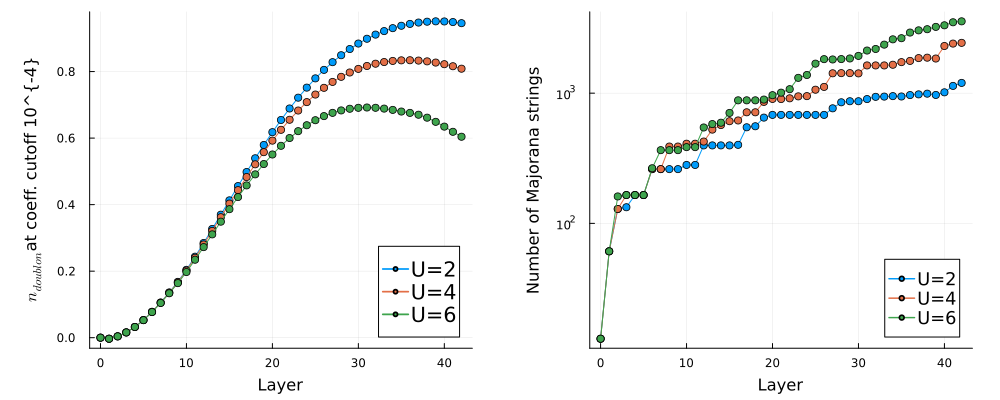

In [123]:
obs_doubl1 = VectorMajoranaSum(MajoranaSum(N_spinful_sites, :nupndn, 1)) #n_1 doublon
obs_doubl2 = VectorMajoranaSum(MajoranaSum(N_spinful_sites, :nupndn, 2)) #n_2 doublon
obs_doubl3 = VectorMajoranaSum(MajoranaSum(N_spinful_sites, :nupndn, 3)) #n_3 doublon
obs_doubl4 = VectorMajoranaSum(MajoranaSum(N_spinful_sites, :nupndn, 4)) #n_4_doublon

obs_doubl=obs_doubl1+obs_doubl2+obs_doubl3+obs_doubl4

res1 = zeros(n_layers+1)
res2 = zeros(n_layers+1)
res3 = zeros(n_layers+1)
length1 = zeros(n_layers+1)
length2 = zeros(n_layers+1)
length3 = zeros(n_layers+1)

res1[1]=overlapwithfock(obs_doubl, initial_state, coeffs)
length1[1] = length(obs_doubl)
res2[1]=overlapwithfock(obs_doubl, initial_state, coeffs)
length2[1] = length(obs_doubl)
res3[1]=overlapwithfock(obs_doubl, initial_state, coeffs)
length3[1] = length(obs_doubl)

#simulation of n_doublon for different values of U, coefficient truncation at 1.e-4
for j = 1:n_layers 
    print("$j ")
    propagate!(circ_single1, obs_doubl, thetas_single1; min_abs_coeff=min_abs_coeff,max_unpaired=max_unpaired, unpaired_mask=unpaired_mask)
    res1[j+1] = overlapwithfock(obs_doubl, initial_state, coeffs)
    length1[j+1] = length(obs_doubl)
end
obs_doubl=obs_doubl1+obs_doubl2+obs_doubl3+obs_doubl4
for j = 1:n_layers 
    print("$j ")
    propagate!(circ_single2, obs_doubl, thetas_single2; min_abs_coeff=min_abs_coeff,max_unpaired=max_unpaired, unpaired_mask=unpaired_mask)
    res2[j+1] = overlapwithfock(obs_doubl, initial_state, coeffs)
    length2[j+1] = length(obs_doubl)
end
obs_doubl=obs_doubl1+obs_doubl2+obs_doubl3+obs_doubl4
for j = 1:n_layers 
    print("$j ")
    propagate!(circ_single3, obs_doubl, thetas_single3; min_abs_coeff=min_abs_coeff,max_unpaired=max_unpaired, unpaired_mask=unpaired_mask)
    res3[j+1] = overlapwithfock(obs_doubl, initial_state, coeffs)
    length3[j+1] = length(obs_doubl)
end

ev_plot = plot(xlabel = "Layer", ylabel = L"n_{doublon}"*"at coeff. cutoff " *"10^{-4}", legend = :bottomright, legend_font_pointsize = 14)
plot!(ev_plot, 0:n_layers, res1, label="U=2", marker=:circle)
plot!(ev_plot, 0:n_layers, res2, label="U=4", marker=:circle)
plot!(ev_plot, 0:n_layers, res3, label="U=6", marker=:circle)

length_plot = plot(xlabel = "Layer",ylabel = "Number of Majorana strings", yscale = :log10, legend = :bottomright,legend_font_pointsize = 12)
plot!(length_plot, 0:n_layers, length1, label="U=2", marker=:circle)
plot!(length_plot, 0:n_layers, length2, label="U=4", marker=:circle)
plot!(length_plot, 0:n_layers, length3, label="U=6", marker=:circle)

plot(ev_plot, length_plot, layout=(1,2), size=(1000,400),left_margin = 10mm, bottom_margin = 5mm, right_margin = 5mm)

Now considering a 2x4 Grid 

In [126]:
N_x = 2
N_y = 4
N_spinful_sites = N_x * N_y
t = 1
U = 2.

n_layers = 15
dt = 0.01

min_abs_coeff = 1.e-4
max_unpaired = 4
unpaired_mask = create_unpaired_mask(2 * N_spinful_sites);

topo = rectangletopology(N_x, N_y,periodic=true)

circ_single = []
thetas_single = []

#up hoppings 
for (i, j) in topo
    push!(circ_single, FermionicGate(:hopup, [i, j]))
    push!(thetas_single, -t * dt)
end

#down hoppings 
for (i, j) in topo
    push!(circ_single, FermionicGate(:hopdn, [i, j]))
    push!(thetas_single, -t * dt)
end

#on-site repulsion 
for i = 1:N_spinful_sites
    push!(circ_single, FermionicGate(:nupndn, i))
    push!(thetas_single, U * dt)
end



1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 

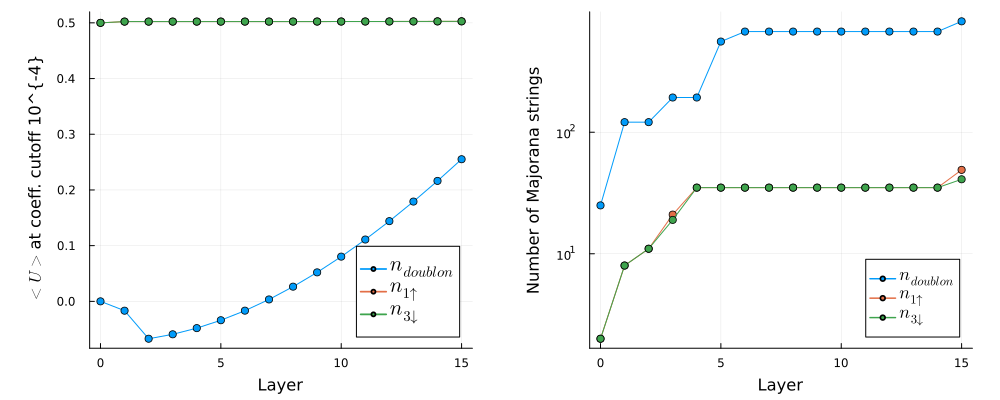

In [127]:
#initial state
is_spinful = true
initial_state11 = FockState(N_spinful_sites, [1,3,4,7],[2,5,6,8])
initial_state12 = FockState(N_spinful_sites, [1,3,4,8],[2,5,6,7])
initial_state13 = FockState(N_spinful_sites, [1,3,6,7],[2,4,5,8])
initial_state14 = FockState(N_spinful_sites, [1,3,6,8],[2,4,5,7])  

initial_state21 = FockState(N_spinful_sites, [1,5,4,7],[2,3,6,8])
initial_state22 = FockState(N_spinful_sites, [1,5,4,8],[2,3,6,7])
initial_state23 = FockState(N_spinful_sites, [1,5,6,7],[2,3,4,8])
initial_state24 = FockState(N_spinful_sites, [1,5,6,8],[2,3,4,7])

initial_state31 = FockState(N_spinful_sites, [2,3,4,7],[1,5,6,8])
initial_state32 = FockState(N_spinful_sites, [2,3,4,8],[1,5,6,7])
initial_state33 = FockState(N_spinful_sites, [2,3,6,7],[1,4,5,8])
initial_state34 = FockState(N_spinful_sites, [2,3,6,8],[1,4,5,7])

initial_state41 = FockState(N_spinful_sites, [2,4,5,7],[1,3,6,8])
initial_state42 = FockState(N_spinful_sites, [2,4,5,8],[1,3,6,7])
initial_state43 = FockState(N_spinful_sites, [2,5,6,7],[1,3,4,8])
initial_state44 = FockState(N_spinful_sites, [2,5,6,8],[1,3,4,7])

initial_state = [initial_state11, initial_state12, initial_state13, initial_state14,
    initial_state21, initial_state22, initial_state23, initial_state24,
    initial_state31, initial_state32, initial_state33, initial_state34,
    initial_state41, initial_state42, initial_state43, initial_state44]
coeffs = [1/4,1/4,1/4,1/4,1/4,1/4,1/4,1/4,1/4,1/4,1/4,1/4,1/4,1/4,1/4,1/4]


#observables
obs_doubl1 = VectorMajoranaSum(MajoranaSum(N_spinful_sites, :nupndn, 1)) #n_1 doublon
obs_doubl2 = VectorMajoranaSum(MajoranaSum(N_spinful_sites, :nupndn, 2)) #n_2 doublon
obs_doubl3 = VectorMajoranaSum(MajoranaSum(N_spinful_sites, :nupndn, 3)) #n_3 doublon
obs_doubl4 = VectorMajoranaSum(MajoranaSum(N_spinful_sites, :nupndn, 4)) #n_4_doublon
obs_doubl5 = VectorMajoranaSum(MajoranaSum(N_spinful_sites, :nupndn, 5)) #n_5 doublon
obs_doubl6 = VectorMajoranaSum(MajoranaSum(N_spinful_sites, :nupndn, 6)) #n_6 doublon
obs_doubl7 = VectorMajoranaSum(MajoranaSum(N_spinful_sites, :nupndn, 7)) #n_7 doublon
obs_doubl8 = VectorMajoranaSum(MajoranaSum(N_spinful_sites, :nupndn, 8)) #n_8 doublon

obs_doubl=obs_doubl1+obs_doubl2+obs_doubl3+obs_doubl4+obs_doubl5+obs_doubl6+obs_doubl7+obs_doubl8
obs2=VectorMajoranaSum(MajoranaSum(N_spinful_sites, :nup, 1)) #n_1 up
obs3= VectorMajoranaSum(MajoranaSum(N_spinful_sites, :ndn, 3)) #n_3 down

res1 = zeros(n_layers+1)
res2 = zeros(n_layers+1)
res3 = zeros(n_layers+1)
length1 = zeros(n_layers+1)
length2 = zeros(n_layers+1)
length3 = zeros(n_layers+1)

res1[1]=overlapwithfock(obs_doubl, initial_state, coeffs)
length1[1] = length(obs_doubl)
res2[1]=overlapwithfock(obs2, initial_state, coeffs)
length2[1] = length(obs2)
res3[1]=overlapwithfock(obs3, initial_state, coeffs)
length3[1] = length(obs3)

#simulation of expectation values for U=2, coefficient truncation at 1.e-4
for j = 1:n_layers 
    print("$j ")
    propagate!(circ_single, obs_doubl, thetas_single; min_abs_coeff=min_abs_coeff,max_unpaired=max_unpaired, unpaired_mask=unpaired_mask)
    propagate!(circ_single, obs2, thetas_single; min_abs_coeff=min_abs_coeff,max_unpaired=max_unpaired, unpaired_mask=unpaired_mask)
    propagate!(circ_single, obs3, thetas_single; min_abs_coeff=min_abs_coeff,max_unpaired=max_unpaired, unpaired_mask=unpaired_mask)
    res1[j+1] = overlapwithfock(obs_doubl, initial_state, coeffs)
    length1[j+1] = length(obs_doubl)
    res2[j+1] = overlapwithfock(obs2, initial_state, coeffs)
    length2[j+1] = length(obs2)
    res3[j+1] = overlapwithfock(obs3, initial_state, coeffs)
    length3[j+1] = length(obs3)
end

ev_plot = plot(xlabel = "Layer", ylabel = L"<U>"*"at coeff. cutoff " *"10^{-4}", legend = :bottomright, legend_font_pointsize = 14)
plot!(ev_plot, 0:n_layers, res1, label=L"n_{doublon}", marker=:circle)
plot!(ev_plot, 0:n_layers, res2, label=L"n_{1↑}", marker=:circle)
plot!(ev_plot, 0:n_layers, res3, label=L"n_{3↓}", marker=:circle)

length_plot = plot(xlabel = "Layer",ylabel = "Number of Majorana strings", yscale = :log10, legend = :bottomright,legend_font_pointsize = 12)
plot!(length_plot, 0:n_layers, length1, label=L"n_{doublon}", marker=:circle)
plot!(length_plot, 0:n_layers, length2, label=L"n_{1↑}", marker=:circle)
plot!(length_plot, 0:n_layers, length3, label=L"n_{3↓}", marker=:circle)

plot(ev_plot, length_plot, layout=(1,2), size=(1000,400),left_margin = 10mm, bottom_margin = 5mm, right_margin = 5mm)

